# **1. Download and Load Dataset**

- Use kagglehub to access GTSRB and store the dataset location in path.
- This gives the notebook a reproducible way to access the dataset
- Dataset Link: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/data

In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")
print(Path("/content/drive/MyDrive/ARTI502_Project/data").is_dir())

Mounted at /content/drive
True


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.


- **Result:** Colab used a cached copy at path: /kaggle/input/gtsrb-german-traffic-sign

## **2. Inspect the Dataset Structure**

- List the files and folders in the dataset directory.
- This identifies where the images and their metadata are stored.

In [4]:
from pathlib import Path
import pandas as pd
import os

dataset_dir= Path("/kaggle/input/gtsrb-german-traffic-sign")

# List the contents of the dataset directory
print("Top-level contents:")
for item in os.listdir(dataset_dir):
    item_path = os.path.join(dataset_dir, item)
    if os.path.isdir(item_path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

Top-level contents:
📁 Meta/
📁 meta/
📄 Meta.csv
📄 Train.csv
📄 Test.csv
📁 Test/
📁 test/
📁 Train/
📁 train/


- The directory contains `Train.csv`, `Test.csv`, and `Meta.csv`, plus folders such as `Train/` and `train/`.

## **3. Load Training Metadata and Inspect Class Folders**
- Load `Train.csv` into a DataFrame and count the images in the first ten class folders listed.
- This shows how the training images are organized and gives an initial view of how image counts vary by class.

In [5]:
# Let's look inside the 'train' folder

train = pd.read_csv(dataset_dir / "Train.csv")
train_path = os.path.join(dataset_dir, "train")

print(f"\nClasses in train folder (first 10):")
classes = sorted(os.listdir(train_path))
for i, class_name in enumerate(classes[:10]):
    class_path = os.path.join(train_path, class_name)
    num_images = len(os.listdir(class_path))
    print(f"  {i}: {class_name} - {num_images} images")

print(f"\nTotal classes: {len(classes)}")


Classes in train folder (first 10):
  0: 0 - 210 images
  1: 1 - 2220 images
  2: 10 - 2010 images
  3: 11 - 1320 images
  4: 12 - 2100 images
  5: 13 - 2160 images
  6: 14 - 780 images
  7: 15 - 630 images
  8: 16 - 420 images
  9: 17 - 1110 images

Total classes: 43


- The training directory has **43 class folders**. Class 0 has 210 images, while class 1 has 2,220 images.

## **4. Map Class IDs to Traffic Sign Names**
- Add a ClassName column by mapping each numeric ClassId to its sign name.
- Sign names make the charts and sample images easier to read. The numeric IDs remain the labels for model training.

In [6]:
classes = { 0:'Speed limit (20km/h)',
            1:'Speed limit (30km/h)',
            2:'Speed limit (50km/h)',
            3:'Speed limit (60km/h)',
            4:'Speed limit (70km/h)',
            5:'Speed limit (80km/h)',
            6:'End of speed limit (80km/h)',
            7:'Speed limit (100km/h)',
            8:'Speed limit (120km/h)',
            9:'No passing',
            10:'No passing veh over 3.5 tons',
            11:'Right-of-way at intersection',
            12:'Priority road',
            13:'Yield',
            14:'Stop',
            15:'No vehicles',
            16:'Veh > 3.5 tons prohibited',
            17:'No entry',
            18:'General caution',
            19:'Dangerous curve left',
            20:'Dangerous curve right',
            21:'Double curve',
            22:'Bumpy road',
            23:'Slippery road',
            24:'Road narrows on the right',
            25:'Road work',
            26:'Traffic signals',
            27:'Pedestrians',
            28:'Children crossing',
            29:'Bicycles crossing',
            30:'Beware of ice/snow',
            31:'Wild animals crossing',
            32:'End speed + passing limits',
            33:'Turn right ahead',
            34:'Turn left ahead',
            35:'Ahead only',
            36:'Go straight or right',
            37:'Go straight or left',
            38:'Keep right',
            39:'Keep left',
            40:'Roundabout mandatory',
            41:'End of no passing',
            42:'End no passing veh > 3.5 tons' }

In [7]:
train["ClassName"] = train["ClassId"].map(classes)

display(train[["ClassId", "ClassName", "Path"]].head())
print("Missing class names:", train["ClassName"].isna().sum())

,ClassId,ClassName,Path
0,20,Dangerous curve right,Train/20/00020_00000_00000.png
1,20,Dangerous curve right,Train/20/00020_00000_00001.png
2,20,Dangerous curve right,Train/20/00020_00000_00002.png
3,20,Dangerous curve right,Train/20/00020_00000_00003.png
4,20,Dangerous curve right,Train/20/00020_00000_00004.png


Missing class names: 0


- The mapping produced 0 missing names.

## **5. Visualize the Class Distribution**
- Count the images per class in `Train.csv` and plot the counts.
- The chart shows class distribution and provides better interpretation for the data

Total training images: 39,209
Number of classes: 43
Smallest class: Dangerous curve left (210 images)
Largest class: Speed limit (50km/h) (2,250 images)


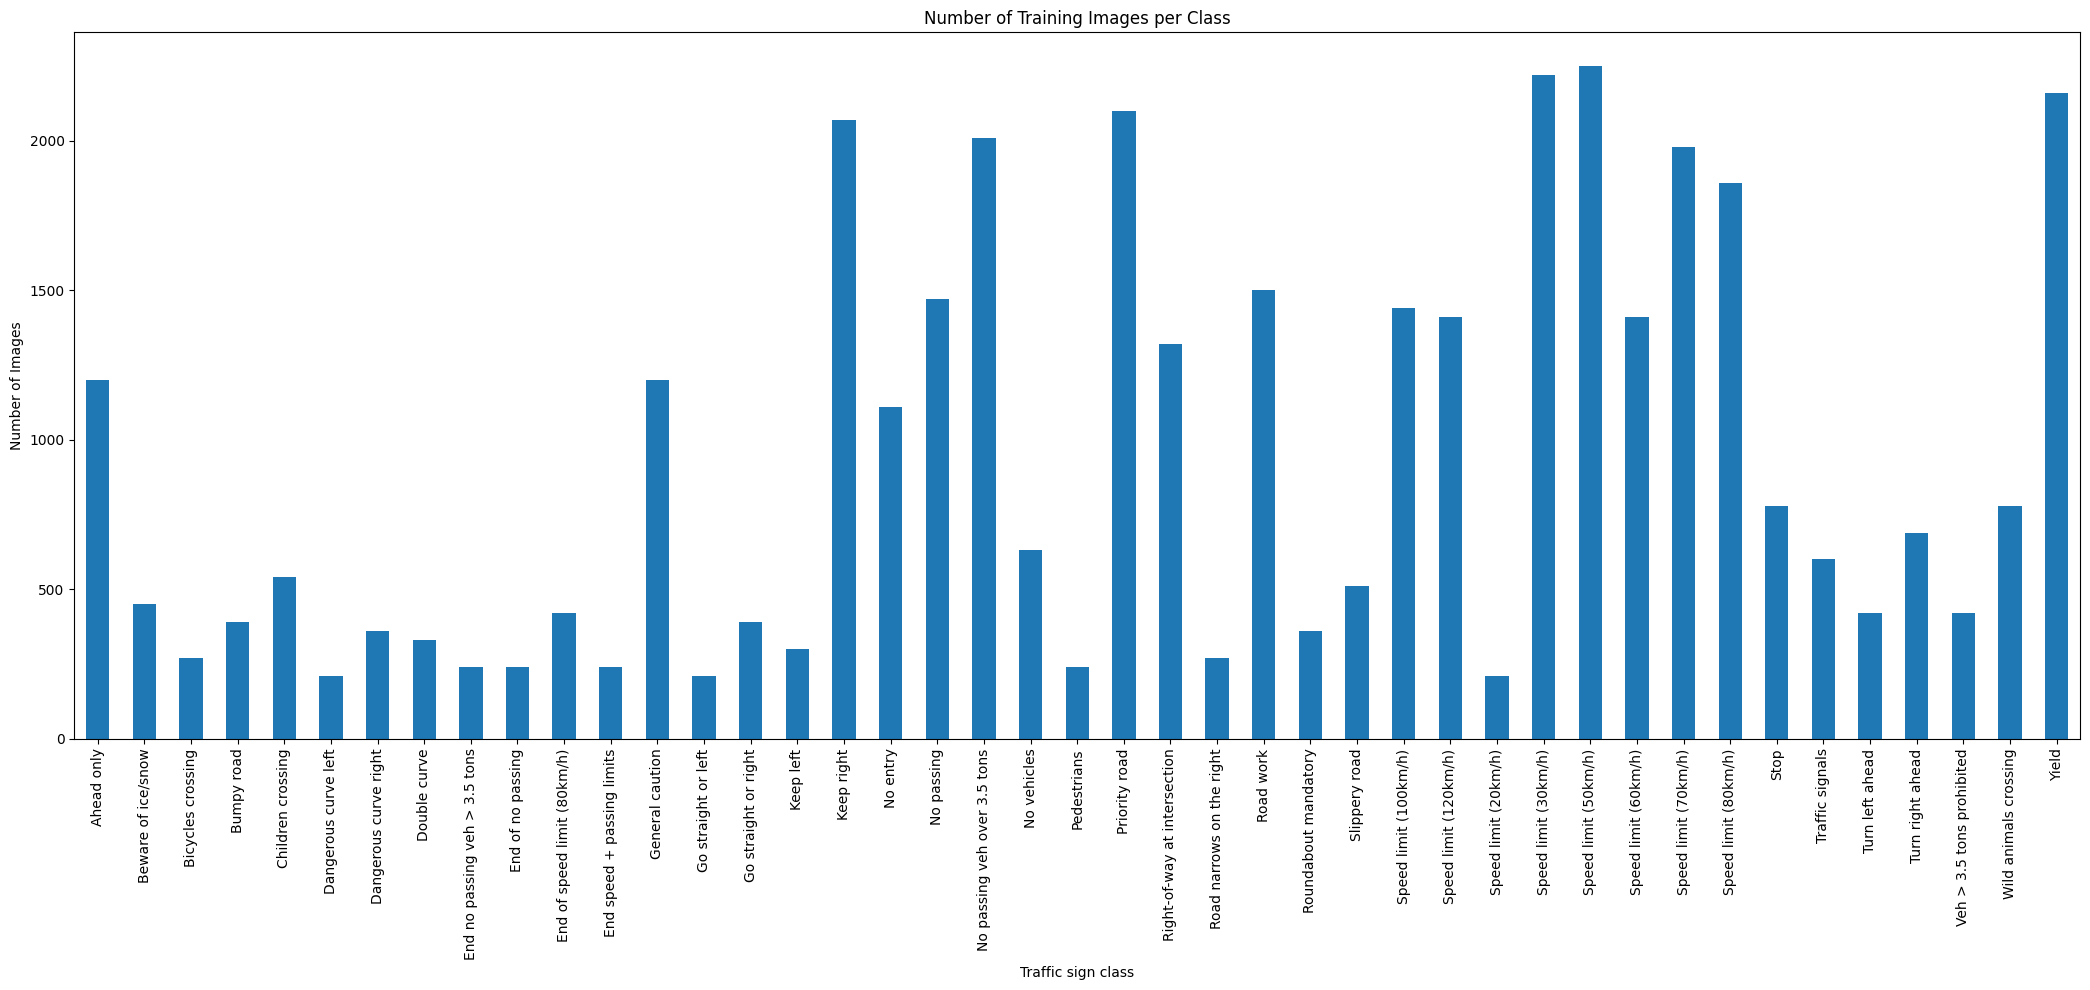

In [8]:
import matplotlib.pyplot as plt

# Count the training images for each class
class_counts = train["ClassName"].value_counts().sort_index()

print(f"Total training images: {len(train):,}")
print(f"Number of classes: {len(class_counts)}")
print(f"Smallest class: {class_counts.idxmin()} ({class_counts.min():,} images)")
print(f"Largest class: {class_counts.idxmax()} ({class_counts.max():,} images)")

class_counts.plot(kind="bar", figsize=(21, 10))
plt.title("Number of Training Images per Class")
plt.xlabel("Traffic sign class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

- The chart shows class imbalance, differences in model performance across classes may occur.
- There are **39,209** images across **43** classes.
- Dangerous curve left is **the least** represented classes with **210** images
- Speed limit (50 km/h) is **the most** represented with **2,250** images.

## **6. Visualize Dataset Samples**
- Display five training images from different classes.
- This lets us visually check the labels and see how the images vary in colors, sizes, and resolution.

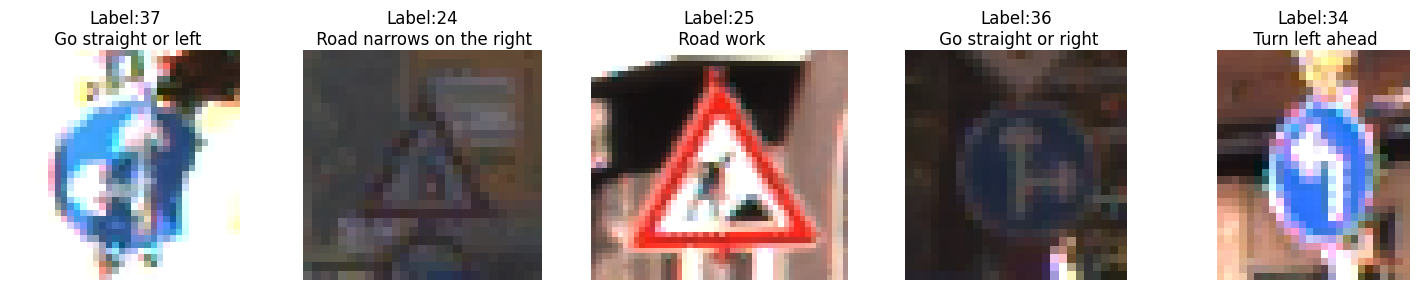

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

# Pick five random images from different classes
samples = train.drop_duplicates(subset="ClassId").sample(
    n=5, random_state=42
)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for ax, (_, row) in zip(axes, samples.iterrows()):
    with Image.open(dataset_dir / row["Path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"Label:{row['ClassId']}\n {row['ClassName']}", wrap=True)
    ax.axis("off")

plt.tight_layout()
plt.show()

- **Result:** The images vary in brightness and clarity, and size.

## **7. Incpect image Size Statistics**
- Calculate the minimum, median, mean, standard deviation, and maximum of the recorded image widths and heights.
- The original dimensions vary, so the images need to resize into a common size before they can be batched for training.

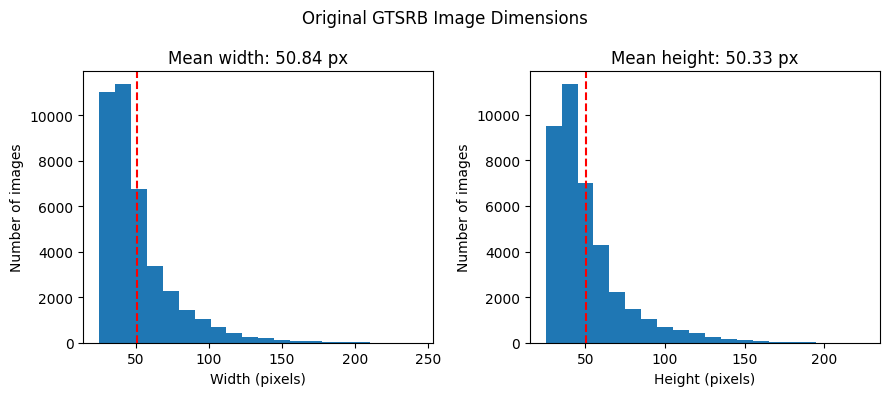

In [18]:
width_plot, height_plot = train[["Width", "Height"]].hist(bins=20, figsize=(9, 4), grid=False).ravel()

mean_width = train["Width"].mean()
mean_height = train["Height"].mean()

width_plot.axvline(mean_width, color="red", linestyle="--")
width_plot.set_title(f"Mean width: {mean_width:.2f} px")
width_plot.set_xlabel("Width (pixels)")
width_plot.set_ylabel("Number of images")

height_plot.axvline(mean_height, color="red", linestyle="--")
height_plot.set_title(f"Mean height: {mean_height:.2f} px")
height_plot.set_xlabel("Height (pixels)")
height_plot.set_ylabel("Number of images")

plt.suptitle("Original GTSRB Image Dimensions")
plt.tight_layout()
plt.show()

In [11]:
# the original image dimensions in pixels
train[["Width", "Height"]].describe()


,Width,Height
count,39209.000000,39209.000000
mean,50.835880,50.328930
std,24.306933,23.115423
min,25.000000,25.000000
25%,35.000000,35.000000
50%,43.000000,43.000000
75%,58.000000,58.000000
max,243.000000,225.000000


- Widths range from **25 to 243** pixels, and heights range from **25 to 225** pixels. Both medians are **43** pixels. The mean width is **50.84** pixels, and the mean height is **50.33** pixels.

## **8. Data Quality**
- Check for missing or repeated labels, paths, and missing or unreadable image files.
- The check helps in catching data issues that could interrupt preprocessing or training.

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39209 entries, 0 to 39208
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Width      39209 non-null  int64 
 1   Height     39209 non-null  int64 
 2   Roi.X1     39209 non-null  int64 
 3   Roi.Y1     39209 non-null  int64 
 4   Roi.X2     39209 non-null  int64 
 5   Roi.Y2     39209 non-null  int64 
 6   ClassId    39209 non-null  int64 
 7   Path       39209 non-null  object
 8   ClassName  39209 non-null  object
dtypes: int64(7), object(2)
memory usage: 2.7+ MB


In [ ]:
# 2 levels of checks to ensure Data quality:
from PIL import Image

print("Missing class IDs:", train["ClassId"].isna().sum())
print(" Missing class names:".lstrip(), train["ClassName"].isna().sum())
print("Missing image paths:", train["Path"].isna().sum())
print("Repeated image paths:", train["Path"].dropna().duplicated().sum())

unreadable_images = []

for relative_path in train["Path"].dropna().unique():
    try:
        with Image.open(dataset_dir / relative_path) as image:
            image.load()
    except OSError:
        unreadable_images.append(relative_path)

print("Missing or unreadable image files:", len(unreadable_images))

if unreadable_images:
    print("First five affected paths:", unreadable_images[:5])

Missing class IDs: 0
Missing class names: 0
Missing image paths: 0
Repeated image paths: 0
Missing or unreadable image files: 0


All checks returned **0**. Everything is unique, not missing, and readable.

## **9. Split the Training Data**
- Split the tracks approximately 80/20 into training and validation, and use a fixed seed of 42.
- A track contains multiple frames of the same physical sign. Keeping each track in one split prevents the model from seeing frames of the same sign during both training and validation.

In [ ]:
from sklearn.model_selection import train_test_split

# Extract the class and track from each filename
train["TrackGroup"] = train["Path"].str.extract(
    r"/(\d+_\d+)_\d+\.png$", expand=False
)
assert train["TrackGroup"].notna().all(), "filenames did not match."

# Split one row per track, preserving the class distribution across tracks
tracks = train[["TrackGroup", "ClassId"]].drop_duplicates()

train_tracks, val_tracks = train_test_split(
    tracks,
    test_size=0.20,
    random_state=42,
    stratify=tracks["ClassId"],
)

# Put all images from each track into the same split
train_df = train[train["TrackGroup"].isin(train_tracks["TrackGroup"])].copy()
val_df = train[train["TrackGroup"].isin(val_tracks["TrackGroup"])].copy()

assert set(train_df["TrackGroup"]).isdisjoint(val_df["TrackGroup"])
assert len(train_df) + len(val_df) == len(train)

print(f"Training: {len(train_df):,} images, {train_df['ClassId'].nunique()} classes")
print(f"Validation: {len(val_df):,} images, {val_df['ClassId'].nunique()} classes")

Training: 31,350 images, 43 classes
Validation: 7,859 images, 43 classes


- The training set has **31,350** images, and the validation set has **7,859** images. Both contain **43** classes, with **zero** track overlap.

## **10. Load the Official Test Set and Save the Splits**
- Load `Test.csv`, map its class IDs to sign names, and save the training, validation, and test metadata as separate CSV files.

In [ ]:
# Load the original test set for final evaluation
test_df = pd.read_csv(dataset_dir / "Test.csv")
test_df["ClassName"] = test_df["ClassId"].map(classes)

# Save the split files in a writable folder
split_dir = Path("/content/drive/MyDrive/ARTI502_Project/data")
split_dir.mkdir(exist_ok=True)

train_df.to_csv(split_dir / "train_split.csv", index=False)
val_df.to_csv(split_dir / "val_split.csv", index=False)
test_df.to_csv(split_dir / "test_split.csv", index=False)

print(f"Test: {len(test_df):,} images, {test_df['ClassId'].nunique()} classes")
print(f"Split files saved in: {split_dir.resolve()}")

Test: 12,630 images, 43 classes
Split files saved in: /content/drive/.shortcut-targets-by-id/1oZ4Ca10sxar0nCWo0aM_Ozvbw7MiJzo0/ARTI502_Project/data


- The test set has **12,630** images across 43 classes. The three split files were saved in `/content/gtsrb_splits`.

## **11. Preprocess and Verify a Sample Image**
- Load an image from `train_df`, convert it to **RGB**
- resize it to `32 × 32` pixels, and scale its pixel values to [0, 1]. Because the original images have different dimensions. Resizing gives the baseline CNN a consistent input shape
- checking one image first to verify the preprocessing before applying it to a batch.

Class: Dangerous curve right
Image shape: (32, 32, 3)
Data type: float32
Pixel range: 0.153 to 0.455


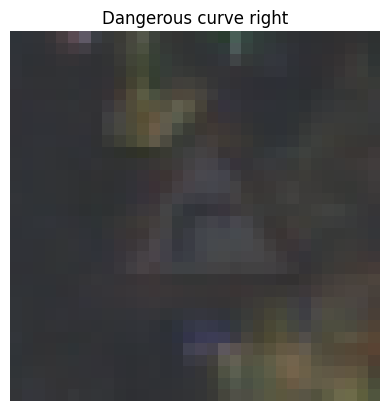

In [ ]:
import numpy as np
from PIL import Image

# Load and preprocess one image for the baseline CNN
def preprocess_image(relative_path, image_size=(32, 32)):
    with Image.open(dataset_dir / relative_path) as image:
        image = image.convert("RGB")
        image = image.resize(image_size, Image.Resampling.BILINEAR)
        return np.asarray(image, dtype=np.float32) / 255.0

sample = train_df.iloc[0]
processed_image = preprocess_image(sample["Path"])

print("Class:", sample["ClassName"])
print("Image shape:", processed_image.shape)
print("Data type:", processed_image.dtype)
print(f"Pixel range: {processed_image.min():.3f} to {processed_image.max():.3f}")

plt.imshow(processed_image)
plt.title(sample["ClassName"])
plt.axis("off")
plt.show()

- The shape is `(32, 32, 3)`, the data type is `float32`, and all pixel values fall between 0 and 1. The image can have a narrower range depending on its colors.

## **12. Load and Verify a Batch of Images**
- Preprocess 32 training images and collect their numeric ClassId labels in the same order.
- The CNN receives images and labels in batches.
- Check one batch to verifies the input shape before building the full data loader.

In [ ]:
batch_rows = train_df.head(32)

X_batch = np.stack([
    preprocess_image(image_path)
    for image_path in batch_rows["Path"]
])

y_batch = batch_rows["ClassId"].to_numpy(dtype=np.int64)

print("Image batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)
print("First five labels:", y_batch[:5])

Image batch shape: (32, 32, 32, 3)
Label batch shape: (32,)
First five labels: [20 20 20 20 20]


- `X_batch` has shape `(32, 32, 32, 3)`:
  - 32 images
  - each 32 × 32 pixels with 3 RGB channels
  
- `y_batch` has shape `(32,)`:
  - with one label per image.

## **13. Build the Data Loaders**
- Load RGB images in batches, resize them to `32 × 32`, scale their pixel values to [0, 1], and pair them with their numeric class IDs.
- The baseline CNN can read batches as needed. We shuffle training data and keep validation and test data in their original order.

In [ ]:
import tensorflow as tf

IMAGE_SIZE = (32, 32)
BATCH_SIZE = 32

def load_image_and_label(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, IMAGE_SIZE) / 255.0
    return image, label

def make_dataset(df, shuffle=False):
    paths = [str(dataset_dir / relative_path) for relative_path in df["Path"]]
    labels = df["ClassId"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df), seed=42, reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Verify the first shuffled training batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 32, 32, 3)
Label batch shape: (32,)
First 10 labels: [12 31 28 38 17 26 38 34 14  4]


- The first training batch still has image shape `(32, 32, 32, 3)` and label shape `(32,)`. The printed labels should now show a mix of classes. Use `train_ds` and `val_ds` for model development and reserve `test_ds` for final evaluation.